# Planetary Defense Analytics — 02: Case 1 Classification (Predict PHA)

**Target:** `pha` (1 = Potentially Hazardous Asteroid, 0 = not)  
**Challenge:** severe imbalance (~0.22% positives) and leakage risk (PHA is *defined* by MOID ≤ 0.05 AU and H ≤ 22).

**Workflow:** load cleaned data → remove leakage → feature engineering → train/test split → feature selection (3 methods) → 3 models × 3 imbalance strategies (tracked in MLflow) → evaluation → save best model → SHAP.

## 1. Setup

In [46]:
import pandas as pd
import numpy as np
import json, os, time, warnings
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, f_classif, mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
import mlflow
import mlflow.sklearn

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
os.makedirs("../models", exist_ok=True)

## 2. Load cleaned data

In [47]:
df = pd.read_parquet("../data/cleaned.parquet")
print("Shape:", df.shape)
print(df['pha'].value_counts())

Shape: (932337, 31)
pha
0    930271
1      2066
Name: count, dtype: int64


## 3. Remove leakage columns

| Column | Why excluded |
|---|---|
| `moid`, `moid_ld` | PHA is defined by MOID ≤ 0.05 AU → model would learn the rule, not a pattern |
| `q` | Perihelion distance, near-duplicate of MOID for near-Earth objects |
| `ad` | `ad = a(1+e)`, indirectly leaks `q` |
| `neo` | Every PHA is a NEO by definition |
| `class` | Expert label; PHAs only occur in APO/ATE/AMO/IEO |
| `diameter`, `albedo` | ~86% missing, and are Case 2 quantities |
| `sigma_q`, `sigma_ad` | Uncertainties of the leaked columns |
| `per` | Duplicate of `per_y` (days vs years) |

In [48]:
leak_cols = ['moid', 'moid_ld', 'q', 'ad', 'neo', 'class', 'diameter', 'albedo',
             'sigma_q', 'sigma_ad', 'per']
data = df.drop(columns=[c for c in leak_cols if c in df.columns])
print("Remaining columns:", list(data.columns))

Remaining columns: ['pha', 'H', 'e', 'a', 'i', 'om', 'w', 'ma', 'n', 'per_y', 'sigma_e', 'sigma_a', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_n', 'sigma_tp', 'sigma_per', 'rms']


## 4. Feature engineering
- **Cyclic angles** `om`, `w`, `ma` (0–360°): 359° and 1° are neighbours, so encode as sin/cos pairs.
- **Log transform** for heavily right-skewed features (`a`, `n`, `per_y`, `sigma_*`, `rms`).
- Rows with remaining nulls (a handful) are dropped.

In [49]:
def engineer_features(d):
    out = pd.DataFrame(index=d.index)
    out['H'] = d['H']
    out['e'] = d['e']
    out['i'] = d['i']
    out['log_a'] = np.log10(d['a'])
    out['log_n'] = np.log10(d['n'])
    out['log_per_y'] = np.log10(d['per_y'])
    for ang in ['om', 'w', 'ma']:
        rad = np.deg2rad(d[ang])
        out[f'{ang}_sin'] = np.sin(rad)
        out[f'{ang}_cos'] = np.cos(rad)
    for s in ['sigma_e', 'sigma_a', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma',
              'sigma_n', 'sigma_tp', 'sigma_per']:
        if s in d.columns:
            out[f'log_{s}'] = np.log10(d[s] + 1e-12)
    if 'rms' in d.columns:
        out['log_rms'] = np.log10(d['rms'] + 1e-6)
    return out

X_all = engineer_features(data)
y_all = data['pha']

mask = X_all.notna().all(axis=1) & np.isfinite(X_all).all(axis=1)
X_all, y_all = X_all[mask], y_all[mask]
print("Feature matrix:", X_all.shape)
print("Positives:", y_all.sum(), f"({y_all.mean()*100:.3f}%)")

Feature matrix: (932335, 22)
Positives: 2066 (0.222%)


## 5. Train / test split
Stratified 80/20 so both sets keep the same ~0.22% PHA ratio. All feature selection and resampling happen on the **training set only**.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| PHA:", y_train.sum())
print("Test :", X_test.shape,  "| PHA:", y_test.sum())

Train: (745868, 22) | PHA: 1653
Test : (186467, 22) | PHA: 413


## 6. Feature selection (3 methods)
Run on a training subsample: **all PHA rows + 100,000 non-PHA rows** (keeps enough positives, runs in reasonable time).

### 6.1 Multicollinearity check

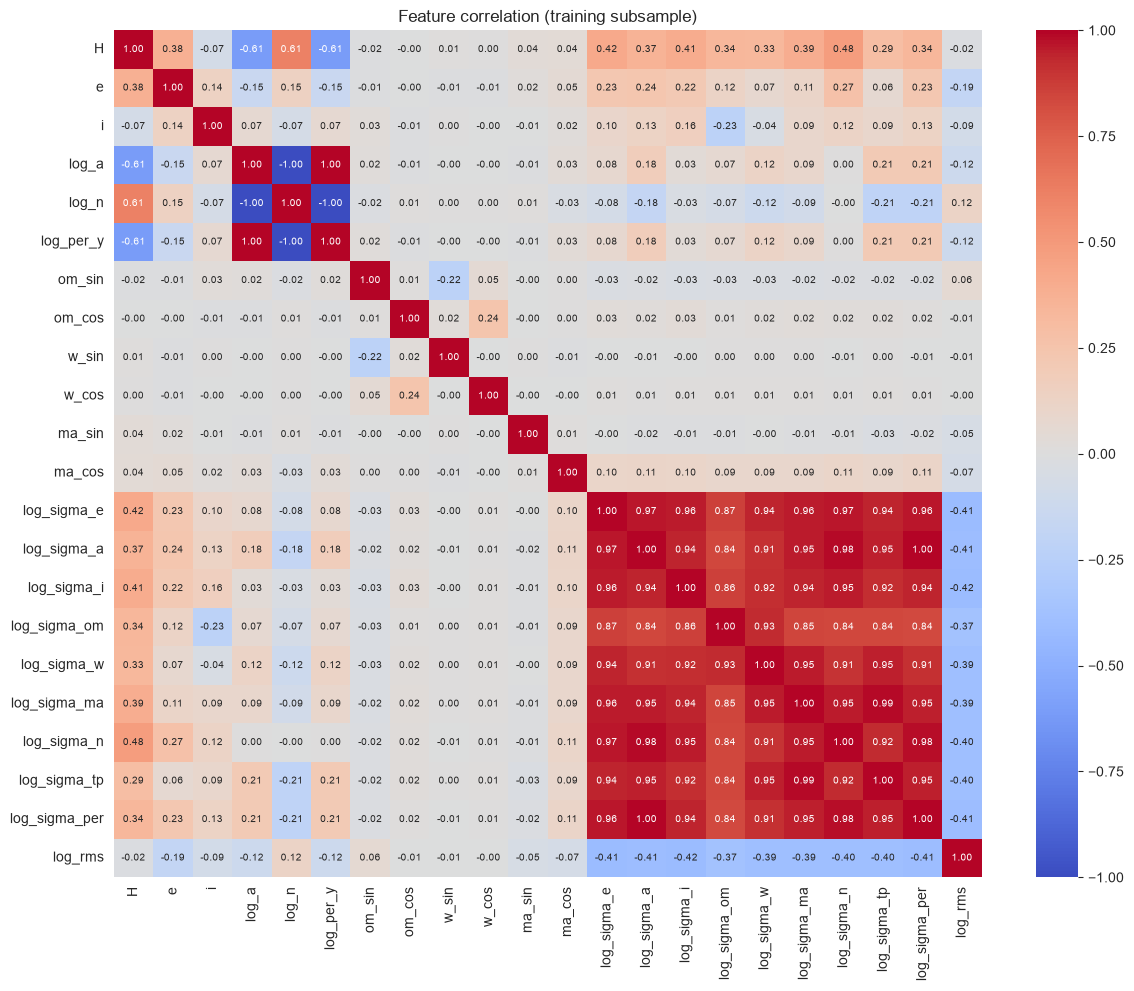

In [51]:
pos = X_train[y_train == 1]
neg = X_train[y_train == 0].sample(100000, random_state=RANDOM_STATE)
X_fs = pd.concat([pos, neg]); y_fs = y_train.loc[X_fs.index]

plt.figure(figsize=(14, 11))
sns.heatmap(X_fs.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Feature correlation (training subsample)"); plt.show()

**Observation:** `log_a`, `log_n` and `log_per_y` are perfectly correlated (|r| ≈ 1) — by Kepler's third law, period and mean motion are fully determined by `a`. Keep only `log_a`. Several `sigma_*` columns are also strongly correlated with each other.

In [52]:
X_fs = X_fs.drop(columns=['log_n', 'log_per_y'])
candidate_features = list(X_fs.columns)
print(len(candidate_features), "candidate features:", candidate_features)

20 candidate features: ['H', 'e', 'i', 'log_a', 'om_sin', 'om_cos', 'w_sin', 'w_cos', 'ma_sin', 'ma_cos', 'log_sigma_e', 'log_sigma_a', 'log_sigma_i', 'log_sigma_om', 'log_sigma_w', 'log_sigma_ma', 'log_sigma_n', 'log_sigma_tp', 'log_sigma_per', 'log_rms']


### 6.2 Method 1 — Statistical tests (ANOVA F-test + Mutual Information)

In [53]:
f_vals, p_vals = f_classif(X_fs, y_fs)
mi = mutual_info_classif(X_fs.sample(50000, random_state=RANDOM_STATE),
                         y_fs.loc[X_fs.sample(50000, random_state=RANDOM_STATE).index],
                         random_state=RANDOM_STATE)
stat_df = pd.DataFrame({'feature': candidate_features, 'anova_F': f_vals,
                        'p_value': p_vals, 'mutual_info': mi}).sort_values('mutual_info', ascending=False)
stat_df

,feature,anova_F,p_value,mutual_info
0,H,5259.956135,0.000000e+00,0.045811
1,e,27409.993603,0.000000e+00,0.044989
3,log_a,5822.012690,0.000000e+00,0.030907
17,log_sigma_tp,64.975997,7.663126e-16,0.018119
18,log_sigma_per,5.966556,1.458142e-02,0.016898
11,log_sigma_a,25.400087,4.666942e-07,0.014824
10,log_sigma_e,58.262019,2.314195e-14,0.009779
14,log_sigma_w,86.817797,1.212705e-20,0.008753
19,log_rms,1073.490340,3.200480e-234,0.008427
12,log_sigma_i,140.307690,2.394615e-32,0.007915


### 6.3 Method 2 — Tree-based feature importance (Random Forest)

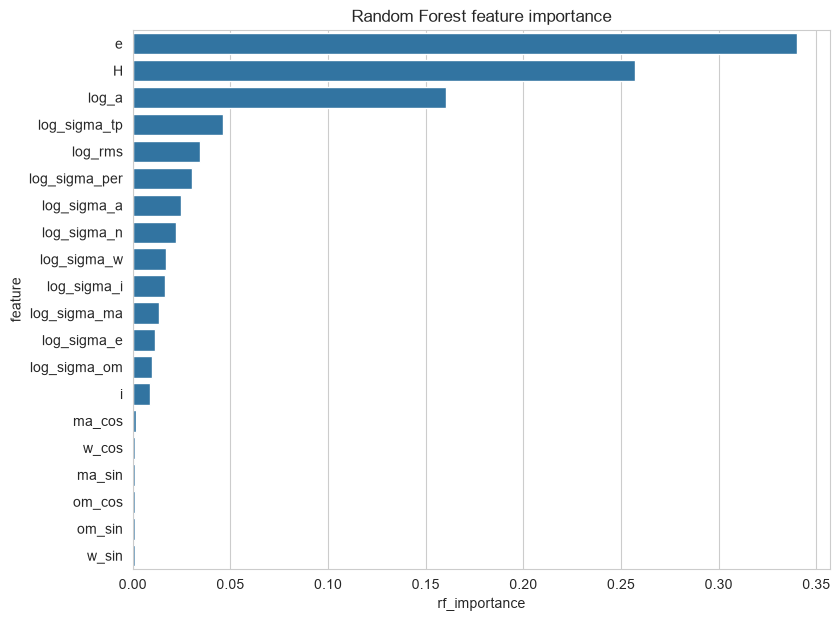

In [54]:
rf_fs = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced',
                               n_jobs=-1, random_state=RANDOM_STATE)
rf_fs.fit(X_fs, y_fs)
imp_df = pd.DataFrame({'feature': candidate_features,
                       'rf_importance': rf_fs.feature_importances_}).sort_values('rf_importance', ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=imp_df, x='rf_importance', y='feature')
plt.title("Random Forest feature importance"); plt.show()

### 6.4 Method 3 — Recursive Feature Elimination (Logistic Regression)

In [55]:
X_fs_scaled = StandardScaler().fit_transform(X_fs)
rfe = RFE(LogisticRegression(max_iter=2000, class_weight='balanced'), n_features_to_select=10)
rfe.fit(X_fs_scaled, y_fs)
rfe_df = pd.DataFrame({'feature': candidate_features, 'rfe_rank': rfe.ranking_}).sort_values('rfe_rank')
rfe_df

,feature,rfe_rank
0,H,1
1,e,1
2,i,1
3,log_a,1
17,log_sigma_tp,1
16,log_sigma_n,1
15,log_sigma_ma,1
13,log_sigma_om,1
12,log_sigma_i,1
10,log_sigma_e,1


### 6.5 Consensus
A feature is kept if it is in the **top 10 of at least 2 of the 3 methods** (Mutual Information, RF importance, RFE). `H` is always kept — it is half of the PHA definition and a genuine physical property.

In [56]:
TOP_K = 10
top_mi  = set(stat_df.nlargest(TOP_K, 'mutual_info')['feature'])
top_rf  = set(imp_df.nlargest(TOP_K, 'rf_importance')['feature'])
top_rfe = set(rfe_df[rfe_df['rfe_rank'] == 1]['feature'])

summary = pd.DataFrame({'feature': candidate_features})
summary['MI_top10']  = summary['feature'].isin(top_mi)
summary['RF_top10']  = summary['feature'].isin(top_rf)
summary['RFE_kept']  = summary['feature'].isin(top_rfe)
summary['votes'] = summary[['MI_top10', 'RF_top10', 'RFE_kept']].sum(axis=1)
summary = summary.sort_values('votes', ascending=False)

selected_features = summary[summary['votes'] >= 2]['feature'].tolist()
if 'H' not in selected_features:
    selected_features.append('H')
print("Selected features:", selected_features)
summary

Selected features: ['H', 'e', 'log_a', 'log_sigma_tp', 'log_sigma_i', 'log_sigma_per', 'log_sigma_n', 'log_sigma_w', 'log_sigma_a', 'log_sigma_e', 'log_rms']


,feature,MI_top10,RF_top10,RFE_kept,votes
0,H,True,True,True,3
1,e,True,True,True,3
3,log_a,True,True,True,3
17,log_sigma_tp,True,True,True,3
12,log_sigma_i,True,True,True,3
18,log_sigma_per,True,True,False,2
16,log_sigma_n,False,True,True,2
14,log_sigma_w,True,True,False,2
11,log_sigma_a,True,True,False,2
10,log_sigma_e,True,False,True,2


## 7. Model training (3 models × 3 imbalance strategies)

| Strategy | How |
|---|---|
| Baseline | No imbalance handling |
| Class weight | `class_weight='balanced'` (LR, RF) / `scale_pos_weight` (XGBoost) |
| SMOTE | Synthetic minority oversampling to a 1:10 ratio, **training data only** (inside the pipeline) |

**Primary selection metric: PR-AUC (average precision)** — threshold-independent and, unlike ROC-AUC, not inflated by the huge number of true negatives. **Recall** is reported alongside because a missed hazardous asteroid is far costlier than a false alarm.

Every run is logged to MLflow (parameters, metrics, model artifact).

In [36]:
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("Case1_PHA_Classification")

Xtr, Xte = X_train[selected_features], X_test[selected_features]
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("neg/pos ratio:", round(neg_pos_ratio, 1))

def build_model(name, strategy):
    if name == "LogisticRegression":
        cw = 'balanced' if strategy == "class_weight" else None
        return LogisticRegression(max_iter=2000, class_weight=cw), True
    if name == "RandomForest":
        cw = 'balanced_subsample' if strategy == "class_weight" else None
        return RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=5,
                                      class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE), False
    if name == "XGBoost":
        spw = neg_pos_ratio if strategy == "class_weight" else 1
        return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                             scale_pos_weight=spw, eval_metric='aucpr',
                             n_jobs=-1, random_state=RANDOM_STATE), False

results, fitted = [], {}
for name in ["LogisticRegression", "RandomForest", "XGBoost"]:
    for strategy in ["baseline", "class_weight", "smote"]:
        t0 = time.time()
        model, needs_scaling = build_model(name, strategy)
        steps = []
        if needs_scaling:
            steps.append(('scaler', StandardScaler()))
        if strategy == "smote":
            steps.append(('smote', SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)))
        steps.append(('model', model))
        pipe = ImbPipeline(steps)

        with mlflow.start_run(run_name=f"{name}_{strategy}"):
            pipe.fit(Xtr, y_train)
            proba = pipe.predict_proba(Xte)[:, 1]
            pred = (proba >= 0.5).astype(int)
            m = {
                'accuracy':  accuracy_score(y_test, pred),
                'precision': precision_score(y_test, pred, zero_division=0),
                'recall':    recall_score(y_test, pred),
                'f1':        f1_score(y_test, pred),
                'pr_auc':    average_precision_score(y_test, proba),
                'roc_auc':   roc_auc_score(y_test, proba),
            }
            mlflow.log_params({'model': name, 'imbalance_strategy': strategy,
                               'n_features': len(selected_features)})
            mlflow.log_params({k: v for k, v in model.get_params().items()
                               if k in ['n_estimators', 'max_depth', 'learning_rate',
                                        'class_weight', 'scale_pos_weight', 'min_samples_leaf']})
            mlflow.log_metrics(m)
            mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")

        key = f"{name}_{strategy}"
        fitted[key] = pipe
        results.append({'run': key, 'model': name, 'strategy': strategy, **m,
                        'train_sec': round(time.time() - t0, 1)})
        print(f"{key:35s} recall={m['recall']:.3f} precision={m['precision']:.3f} "
              f"f1={m['f1']:.3f} pr_auc={m['pr_auc']:.3f}  ({time.time()-t0:.0f}s)")

neg/pos ratio: 450.2


2026/11/07 23:59:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogisticRegression_baseline         recall=0.121 precision=0.316 f1=0.175 pr_auc=0.290  (3s)


2026/11/07 23:59:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogisticRegression_class_weight     recall=0.993 precision=0.129 f1=0.229 pr_auc=0.233  (3s)


2026/11/07 23:59:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (9 outputs left out)

2026/11/08 00:00:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost_class_weight                recall=0.869 precision=0.338 f1=0.487 pr_auc=0.507  (4s)


2026/11/08 00:01:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost_smote                       recall=0.879 precision=0.369 f1=0.520 pr_auc=0.561  (4s)


## 8. Model comparison

In [37]:
res_df = pd.DataFrame(results).sort_values('pr_auc', ascending=False).reset_index(drop=True)
res_df.round(4)

,run,model,strategy,accuracy,precision,recall,f1,pr_auc,roc_auc,train_sec
0,RandomForest_baseline,RandomForest,baseline,0.9980,0.6541,0.2518,0.3636,0.5705,0.9961,25.4
1,XGBoost_smote,XGBoost,smote,0.9964,0.3689,0.8789,0.5197,0.5610,0.9986,4.1
2,XGBoost_class_weight,XGBoost,class_weight,0.9959,0.3380,0.8692,0.4868,0.5067,0.9982,4.0
3,RandomForest_smote,RandomForest,smote,0.9964,0.3694,0.9007,0.5239,0.5054,0.9973,24.0
4,RandomForest_class_weight,RandomForest,class_weight,0.9968,0.3903,0.8184,0.5285,0.4921,0.9973,14.2
5,XGBoost_baseline,XGBoost,baseline,0.9980,0.5599,0.3850,0.4562,0.4896,0.9961,4.1
6,LogisticRegression_baseline,LogisticRegression,baseline,0.9975,0.3165,0.1211,0.1751,0.2900,0.9906,2.9
7,LogisticRegression_smote,LogisticRegression,smote,0.9921,0.2110,0.9322,0.3441,0.2589,0.9938,2.7
8,LogisticRegression_class_weight,LogisticRegression,class_weight,0.9852,0.1294,0.9927,0.2290,0.2325,0.9937,2.7


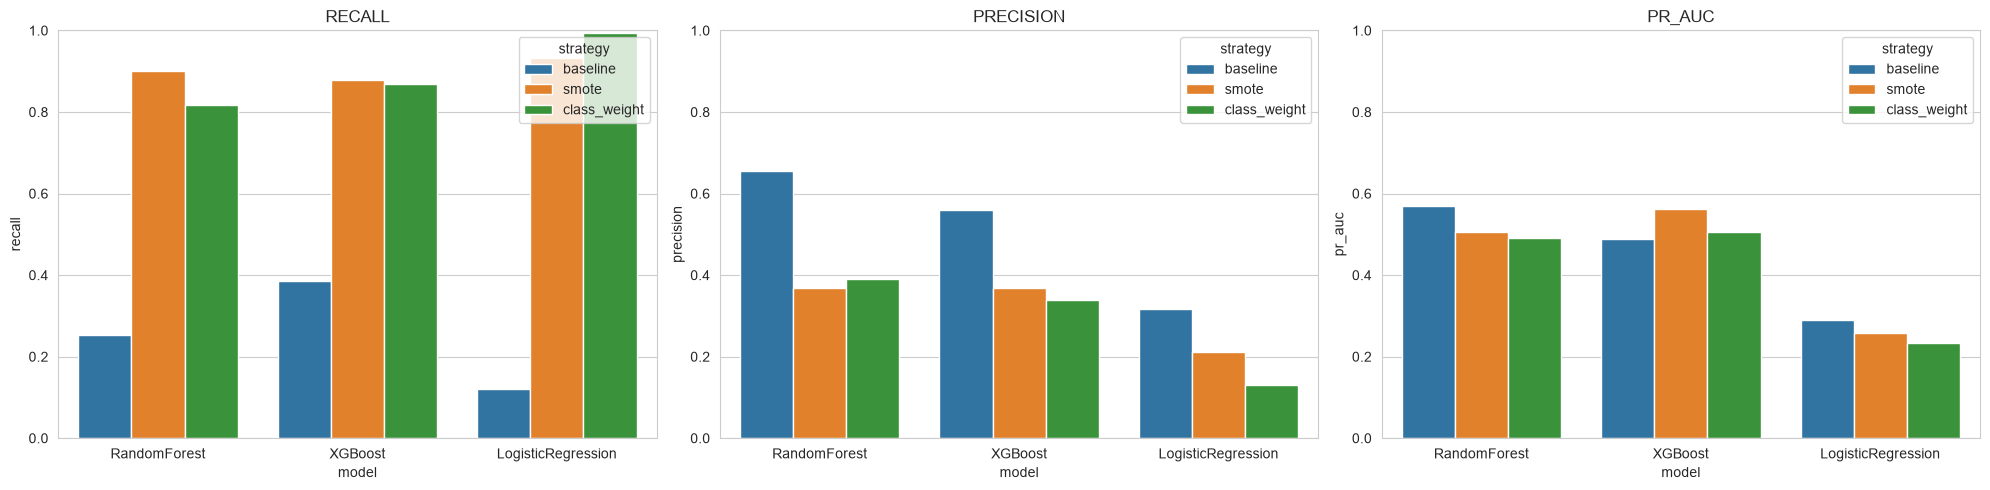

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, metric in zip(axes, ['recall', 'precision', 'pr_auc']):
    sns.barplot(data=res_df, x='model', y=metric, hue='strategy', ax=ax)
    ax.set_title(metric.upper()); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Conclusion:**
- **Accuracy is misleading:** every model scored ~99% accuracy, because predicting "not hazardous" is almost always right (PHAs are only 0.22% of the data).
- **Baseline models miss most hazards:** without imbalance handling, recall was low: Logistic Regression 0.12, Random Forest 0.25, XGBoost 0.39.
- **Imbalance handling raises recall sharply:** class weighting and SMOTE pushed recall to 0.82–0.99, at the cost of lower precision (more false alarms).
- **Logistic Regression with class weighting** had the highest recall (0.99) but very low precision (0.13), so it flags too many safe asteroids.
- **Best balance: XGBoost + SMOTE**: recall 0.879, precision 0.369, F1 0.520, PR-AUC 0.561. It catches ~88% of hazardous asteroids with far fewer false alarms than the benchmark (precision 0.37 vs 0.16).
- **Why recall matters most:** a false alarm only costs extra telescope time; a missed PHA could mean an undetected impact risk.

## 9. Best model — confusion matrix & precision-recall curve

Best model (by PR-AUC): RandomForest_baseline


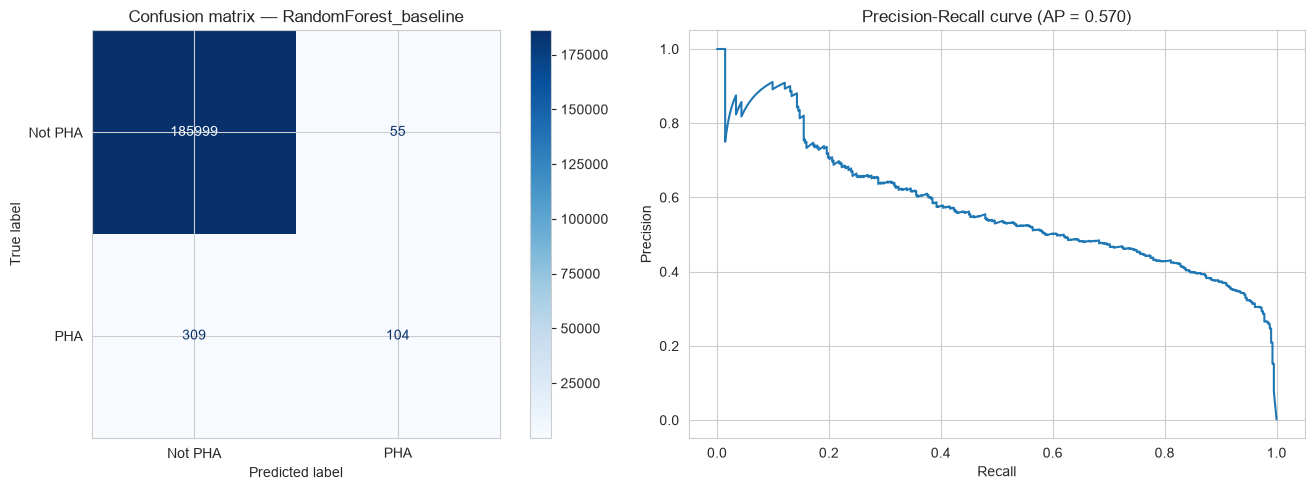

In [39]:
best_key = res_df.loc[0, 'run']
best_pipe = fitted[best_key]
print("Best model (by PR-AUC):", best_key)

proba_best = best_pipe.predict_proba(Xte)[:, 1]
pred_best = (proba_best >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best),
                       display_labels=['Not PHA', 'PHA']).plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title(f"Confusion matrix — {best_key}")

prec, rec, thr = precision_recall_curve(y_test, proba_best)
axes[1].plot(rec, prec)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title(f"Precision-Recall curve (AP = {average_precision_score(y_test, proba_best):.3f})")
plt.tight_layout(); plt.show()

**Interpretation:** the PR curve shows the trade-off — moving along it, catching more hazardous asteroids (higher recall) costs more false alarms (lower precision). For planetary defense, a false alarm only costs extra telescope time; a missed PHA is the costly error, so a high-recall operating point is preferred.

## 10. Save best model

In [40]:
raw_cols = [c for c in ['H', 'e', 'i', 'a', 'om', 'w', 'ma', 'rms',
                        'sigma_e', 'sigma_a', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma',
                        'sigma_n', 'sigma_tp', 'sigma_per'] if c in data.columns]
artifact = {'pipeline': best_pipe, 'features': selected_features, 'model_name': best_key,
            'threshold': 0.5,
            'raw_defaults': data.loc[X_train.index, raw_cols].median().to_dict(),   # used by the app for inputs the user doesn't know
            'background': Xtr.sample(200, random_state=RANDOM_STATE)}               # for SHAP in the app
joblib.dump(artifact, "../models/pha_classifier.joblib", compress=3)
size_mb = os.path.getsize("../models/pha_classifier.joblib") / 1e6
print(f"Saved ../models/pha_classifier.joblib  ({size_mb:.1f} MB)")
if size_mb > 95:
    print("WARNING: file > 95 MB — too large for GitHub. Pick the XGBoost run instead.")

Saved ../models/pha_classifier.joblib  (2.1 MB)


## Deployment decision
RandomForest_baseline had the highest PR-AUC, but it applies no imbalance handling and misses more hazardous asteroids at the default threshold. **XGBoost with scale_pos_weight** is deployed because recall matters most for planetary defense (a missed PHA costs far more than a false alarm), and its SHAP values are in readable log-odds units.

             run  recall  precision      f1  pr_auc
1  XGBoost_smote  0.8789     0.3689  0.5197   0.561
Saved XGBoost_smote: 0.7 MB


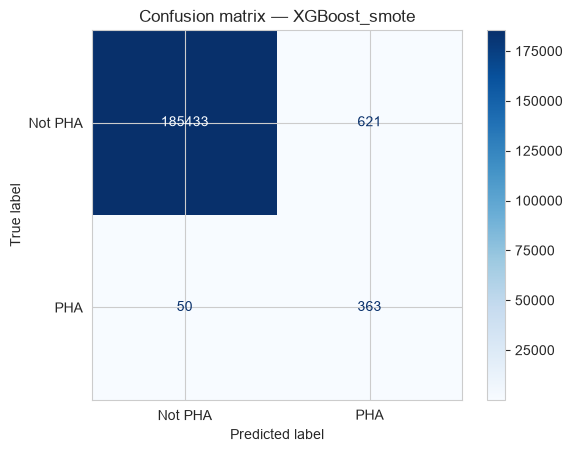

In [41]:
best_key = 'XGBoost_smote'
best_pipe = fitted[best_key]
print(res_df[res_df['run'] == best_key][['run', 'recall', 'precision', 'f1', 'pr_auc']].round(4))

artifact = {'pipeline': best_pipe, 'features': selected_features, 'model_name': best_key,
            'threshold': 0.5,
            'raw_defaults': data.loc[X_train.index, raw_cols].median().to_dict(),
            'background': Xtr.sample(200, random_state=RANDOM_STATE)}
joblib.dump(artifact, "../models/pha_classifier.joblib", compress=3)
print(f"Saved {best_key}: {os.path.getsize('../models/pha_classifier.joblib')/1e6:.1f} MB")

pred_best = best_pipe.predict(Xte)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best),
                       display_labels=['Not PHA', 'PHA']).plot(cmap='Blues', values_format='d')
plt.title(f"Confusion matrix — {best_key}"); plt.show()

## 11. Explainable AI — SHAP
SHAP shows how much each feature pushes a prediction towards or away from "PHA".

In [42]:
import shap

model_step = best_pipe.named_steps['model']
X_shap = Xte.sample(2000, random_state=RANDOM_STATE)
# include some real PHAs so their explanations are visible
X_shap = pd.concat([X_shap, Xte[y_test == 1].head(100)])
X_shap_t = (pd.DataFrame(best_pipe.named_steps['scaler'].transform(X_shap), columns=selected_features, index=X_shap.index)
            if 'scaler' in best_pipe.named_steps else X_shap)

if isinstance(model_step, LogisticRegression):
    explainer = shap.LinearExplainer(model_step, X_shap_t)
else:
    explainer = shap.TreeExplainer(model_step)
sv = explainer(X_shap_t)
if len(sv.values.shape) == 3:          # RandomForest returns one set per class
    sv = sv[:, :, 1]

### 11.1 Global importance (summary / beeswarm)

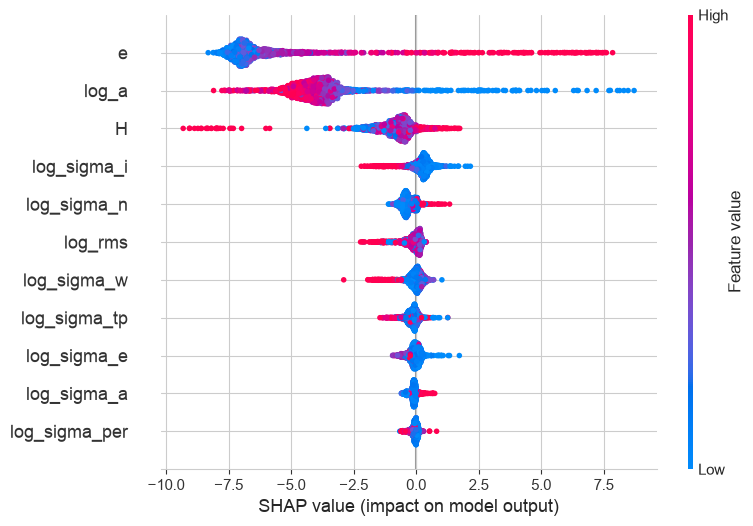

In [43]:
shap.plots.beeswarm(sv, max_display=15)

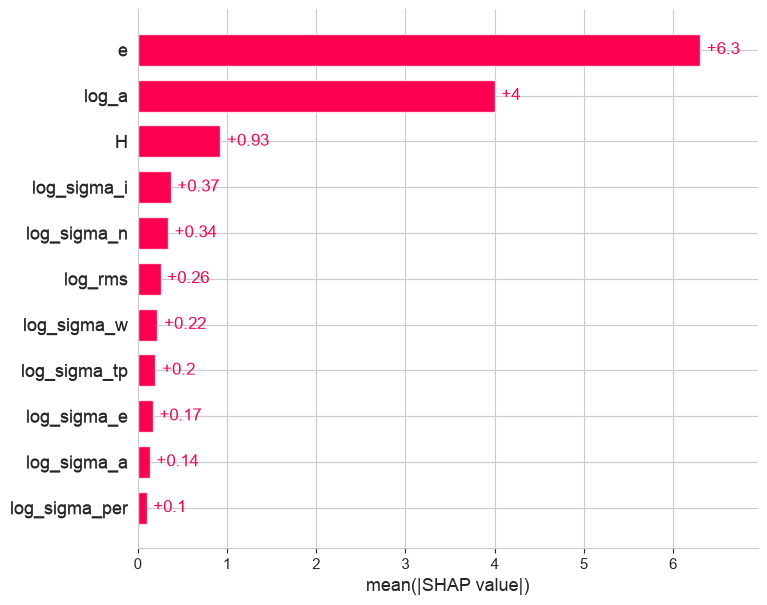

In [44]:
shap.plots.bar(sv, max_display=15)

### 11.2 Local explanation — one real PHA

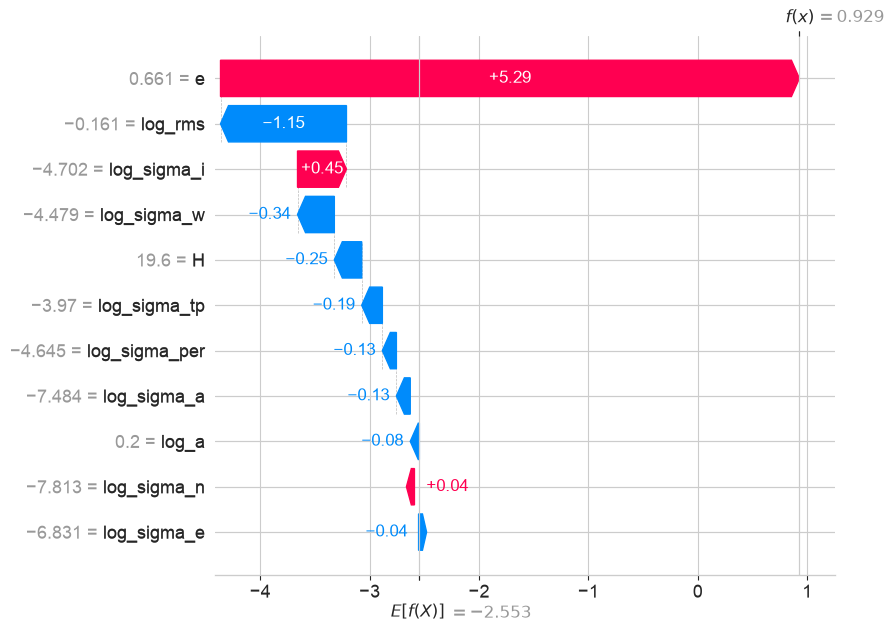

In [45]:
pha_idx = list(X_shap.index).index(Xte[y_test == 1].index[0])
shap.plots.waterfall(sv[pha_idx], max_display=12)

**Discussion:**
- **Top features:** SHAP ranks eccentricity (`e`) and orbit size (`log_a`) highest. High eccentricity with a semi-major axis near 1–2 AU means the orbit stretches into Earth's neighbourhood, which is exactly what makes an asteroid potentially hazardous. Low `e` with a main-belt `log_a` (~2.7 AU) pushes strongly towards "not hazardous".
- **H (absolute magnitude):** contributes but is not dominant on its own. H only matters once the orbit can reach Earth's vicinity (PHA requires H ≤ 22).
- **Orbit-uncertainty features (`log_sigma_*`):** also contribute. These mostly reflect how recently and how well an object has been observed (near-Earth objects are often newer discoveries), so part of their effect is observation bias rather than physics.
- **Agreement with feature selection:** the top SHAP features were also selected by the consensus of statistical tests, Random Forest importance and RFE (Section 6.5), so both methods confirm the same drivers.
- **No leakage:** MOID, q, NEO and class were excluded, so the model learns orbit patterns rather than the PHA definition rule.

## 12. Summary
- Leakage columns removed: `moid`, `moid_ld`, `q`, `ad`, `neo`, `class`.
- Features selected by consensus of statistical tests, RF importance and RFE.
- 9 runs (3 models × 3 imbalance strategies) logged in MLflow → view with `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project folder.
- Best model saved to `models/pha_classifier.joblib` for the Streamlit app.